# Task 1B: Analytical Questions (Part 2)
**Group assignment:** Working with Time Series Data
**Author:** David NGARAMBE (Member 1: exploratory analysis and preprocessing)

Part 1 (`02_analytical_questions_part1.ipynb`) answered Q1 to Q3 and created the lag and moving-average features. This notebook answers the remaining three questions. **Q5 and Q6 are the questions that require lagged features and moving averages**, as the assignment demands.

| # | Analytical question | Technique |
|---|---|---|
| Q4 | Does temperature (an external variable) explain demand? | binned means, scatter density, heating / cooling split |
| Q5 | Are there lag effects: how much does demand depend on the previous hour, day and week? | autocorrelation, lagged scatter plots, naive forecast errors |
| Q6 | Do moving averages reveal structure and help predict demand? | 24-hour and 168-hour moving averages, feature correlations |

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Same colour roles as Part 1: blue = demand, orange = temperature, grey = context
BLUE, ORANGE, GREY, DARK = "#2a78d6", "#eb6834", "#9a9a96", "#333333"

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "lines.linewidth": 1.8, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "figure.dpi": 100,
})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

PROCESSED_DIR = Path("../data/processed")

clean = pd.read_csv(PROCESSED_DIR / "pjme_clean.csv", parse_dates=["Datetime"]).set_index("Datetime")
feat = pd.read_csv(PROCESSED_DIR / "pjme_features.csv", parse_dates=["Datetime"]).set_index("Datetime")
print("Clean series:", clean.shape, "| Feature table:", feat.shape)

Clean series: (145392, 3) | Feature table: (145224, 12)


## Q4. Does temperature explain electricity demand?

**Approach:** Part 1 found that the straight-line link between monthly demand and temperature is weak, which suggests a curved relationship. Here every hour is plotted (density of points), together with the **mean demand within each 2 °C temperature band**. The lowest point of that curve is the "balance point" between heating demand and cooling demand.

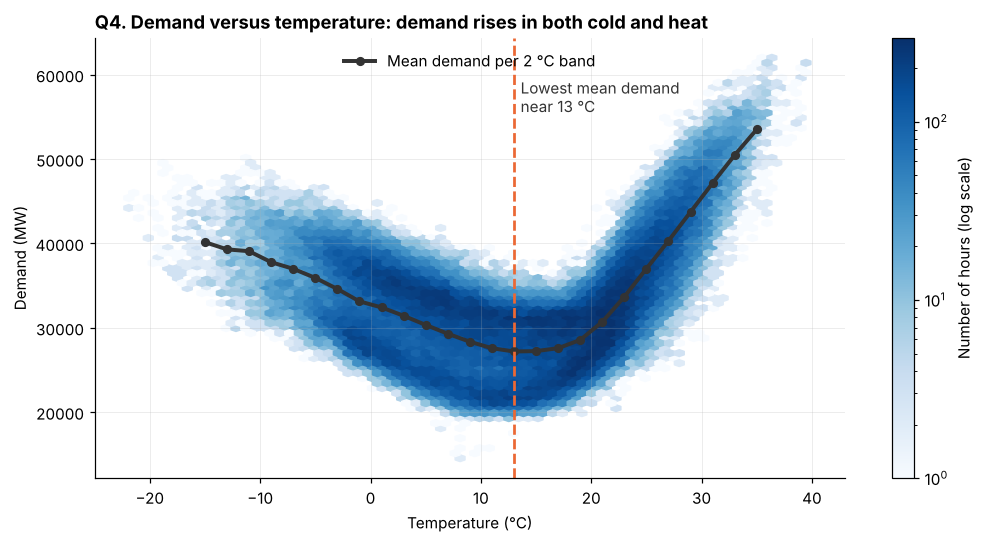

In [2]:
t, d = clean["temperature_c"], clean["PJME_MW"]

edges = np.arange(-22, 42, 2)
band = pd.cut(t, edges)
binned = d.groupby(band, observed=True).agg(mean="mean", hours="size")
binned["mid"] = [iv.mid for iv in binned.index]
binned = binned[binned["hours"] >= 100]                 # ignore bands with too few hours to be reliable

balance = binned["mid"][binned["mean"].idxmin() == binned.index].iloc[0]

fig, ax = plt.subplots(figsize=(11, 5.2))
hb = ax.hexbin(t, d, gridsize=70, cmap="Blues", mincnt=1, bins="log")
ax.plot(binned["mid"], binned["mean"], color=DARK, lw=2.6, marker="o", ms=5, label="Mean demand per 2 °C band")
ax.axvline(balance, color=ORANGE, ls="--", lw=1.8)
ax.text(balance + 0.6, d.max() * 0.96, f"Lowest mean demand\nnear {balance:.0f} °C", color=DARK, va="top")
ax.set(title="Q4. Demand versus temperature: demand rises in both cold and heat",
       xlabel="Temperature (°C)", ylabel="Demand (MW)")
fig.colorbar(hb, ax=ax, label="Number of hours (log scale)")
ax.legend(frameon=False, loc="upper center")
plt.show()

In [3]:
# Quantify: straight line vs curve, and separate slopes below / above the balance point
linear_r = t.corr(d)
quad = np.polyfit(t, d, 2)
pred = np.polyval(quad, t)
r2_quad = 1 - ((d - pred) ** 2).sum() / ((d - d.mean()) ** 2).sum()
print(f"Straight-line correlation: r = {linear_r:.2f}  (R² = {linear_r**2:.3f})")
print(f"Curved (quadratic) fit:    R² = {r2_quad:.3f}")

cold, hot = clean[t < balance], clean[t >= balance]
fc = stats.linregress(cold["temperature_c"], cold["PJME_MW"])
fh = stats.linregress(hot["temperature_c"], hot["PJME_MW"])
print(f"\nBelow {balance:.0f} °C (heating): {fc.slope:+,.0f} MW per °C, r = {fc.rvalue:.2f}, {len(cold):,} hours")
print(f"Above {balance:.0f} °C (cooling): {fh.slope:+,.0f} MW per °C, r = {fh.rvalue:.2f}, {len(hot):,} hours")

bands = pd.cut(t, [-25, -5, 5, 15, 25, 30, 45], labels=["< -5", "-5 to 5", "5 to 15", "15 to 25", "25 to 30", "> 30"])
d.groupby(bands, observed=True).agg(mean_demand=("mean"), hours=("size")).round(0)

Straight-line correlation: r = 0.24  (R² = 0.059)
Curved (quadratic) fit:    R² = 0.539

Below 13 °C (heating): -505 MW per °C, r = -0.56, 71,073 hours
Above 13 °C (cooling): +1,199 MW per °C, r = 0.82, 74,319 hours


,mean_demand,hours
temperature_c,,
< -5,"37,551.00",4951
-5 to 5,"32,578.00",33348
5 to 15,"28,234.00",41385
15 to 25,"30,534.00",47476
25 to 30,"40,689.00",14348
> 30,"48,869.00",3884


**Interpretation**
- **The relationship is a U-shape (a curve), not a line.** Mean demand is lowest, about 27,500 MW, around **13 °C**, where little heating or cooling is needed. It climbs in the cold (37,551 MW below -5 °C) and climbs much more steeply in the heat (**48,869 MW above 30 °C, 73% higher than in the 5 to 15 °C band**).
- A straight line explains only **5.9%** of the variation in demand (r = 0.24), which is why Part 1 and the correlation table looked weak. A curved (quadratic) fit explains **53.9%**, roughly nine times more. Temperature is therefore a strong driver of demand, but only when the curve is modelled.
- **Cooling is more sensitive than heating:** above 13 °C demand rises about **+1,199 MW per °C** (r = 0.82), while below 13 °C it rises about **505 MW per °C** as it gets colder (r = -0.56). One extra degree of summer heat adds roughly 2.4 times as much demand as one extra degree of winter cold.
- The wide vertical spread at any given temperature comes from the time of day and the day of the week (Q2), so temperature is best used together with `hour` and `is_weekend`.
- **Implication for modelling:** use a non-linear model, or add a feature such as the distance from the balance point (`abs(temperature_c - 13)`) so that even a linear model can use temperature. If `temperature_c` is used as an input, it must be known at prediction time, so the group should decide whether to use a forecast or a lagged temperature to avoid leakage.

## Q5. Are there lag effects: how much does demand depend on its own past?

**Approach (uses lagged features):**
1. The **autocorrelation function** shows how strongly demand is correlated with itself at every lag from 1 hour to 2 weeks.
2. Scatter plots of demand against `lag_1`, `lag_24` and `lag_168` show the relationships visually.
3. Each lag is used as a **naive forecast** ("next hour will equal the value one hour / one day / one week ago") and its error is measured. This gives a baseline that any trained model must beat.

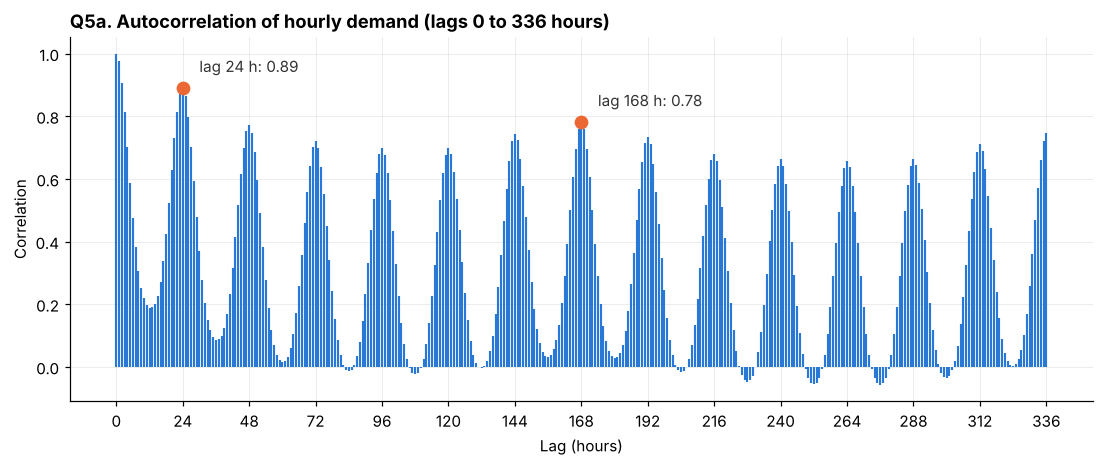

lag_hours,1,2,3,6,12,24,48,168,336
autocorrelation,0.97,0.91,0.81,0.48,0.19,0.89,0.77,0.78,0.75


In [4]:
s = clean["PJME_MW"]
max_lag = 24 * 14
acf = pd.Series([s.autocorr(lag=k) for k in range(0, max_lag + 1)])

fig, ax = plt.subplots(figsize=(12, 4.3))
ax.vlines(acf.index, 0, acf.values, color=BLUE, lw=1.4)
for k in (24, 168):
    ax.plot(k, acf[k], "o", color=ORANGE, ms=8)
    ax.annotate(f"lag {k} h: {acf[k]:.2f}", (k, acf[k]), xytext=(k + 6, acf[k] + 0.05), color=DARK)
ax.set(title="Q5a. Autocorrelation of hourly demand (lags 0 to 336 hours)", xlabel="Lag (hours)", ylabel="Correlation")
ax.set_xticks(range(0, max_lag + 1, 24))
plt.show()
pd.DataFrame({"lag_hours": [1, 2, 3, 6, 12, 24, 48, 168, 336],
              "autocorrelation": [acf[k] for k in (1, 2, 3, 6, 12, 24, 48, 168, 336)]}).set_index("lag_hours").T

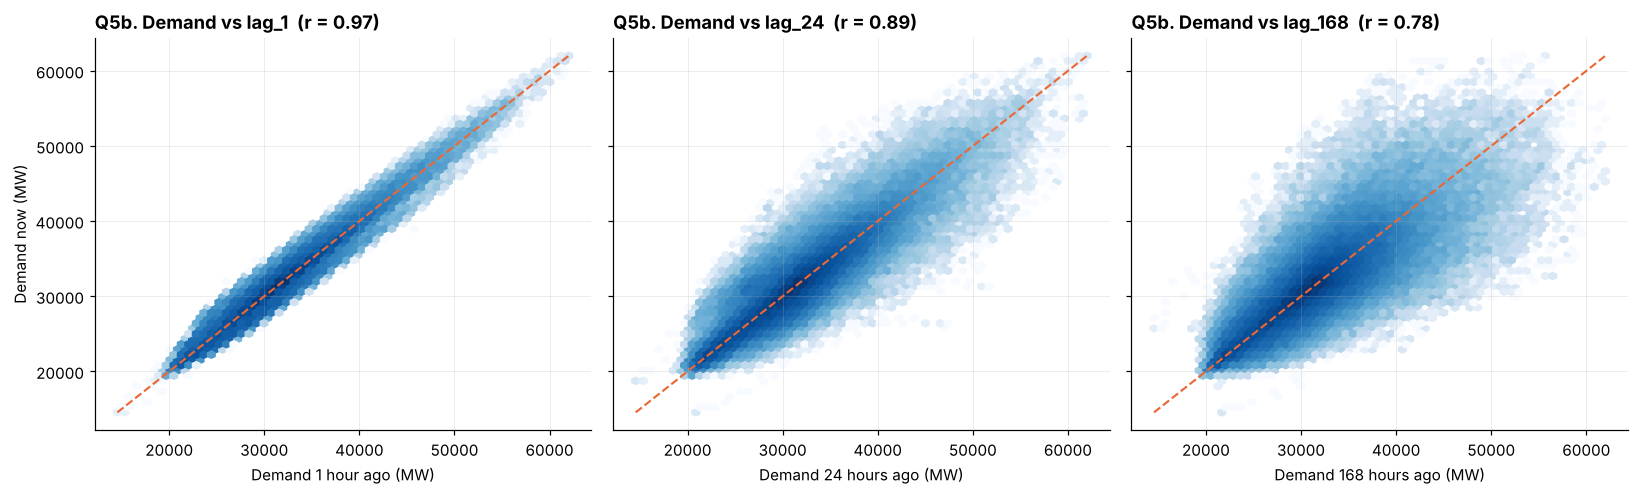

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, col, name in zip(axes, ["lag_1", "lag_24", "lag_168"], ["1 hour ago", "24 hours ago", "168 hours ago"]):
    ax.hexbin(feat[col], feat["PJME_MW"], gridsize=60, cmap="Blues", mincnt=1, bins="log")
    lims = [feat["PJME_MW"].min(), feat["PJME_MW"].max()]
    ax.plot(lims, lims, color=ORANGE, lw=1.4, ls="--")
    r = feat[col].corr(feat["PJME_MW"])
    ax.set(title=f"Q5b. Demand vs {col}  (r = {r:.2f})", xlabel=f"Demand {name} (MW)")
axes[0].set_ylabel("Demand now (MW)")
plt.tight_layout()
plt.show()

In [6]:
# Naive forecasts: predict demand with one existing column and measure the error
def errors(pred, actual=feat["PJME_MW"]):
    e = actual - pred
    return pd.Series({"MAE (MW)": e.abs().mean(), "RMSE (MW)": np.sqrt((e ** 2).mean()),
                      "MAPE (%)": (e.abs() / actual).mean() * 100})

baselines = pd.DataFrame({
    "lag_1 (previous hour)": errors(feat["lag_1"]),
    "lag_24 (same hour yesterday)": errors(feat["lag_24"]),
    "lag_168 (same hour last week)": errors(feat["lag_168"]),
    "rolling_mean_24": errors(feat["rolling_mean_24"]),
    "rolling_mean_168": errors(feat["rolling_mean_168"]),
    "average of lag_24 and lag_168": errors((feat["lag_24"] + feat["lag_168"]) / 2),
}).T.sort_values("MAE (MW)")
baselines

,MAE (MW),RMSE (MW),MAPE (%)
lag_1 (previous hour),"1,109.30","1,451.95",3.53
average of lag_24 and lag_168,"2,116.21","2,880.11",6.47
lag_24 (same hour yesterday),"2,173.19","3,012.51",6.71
lag_168 (same hour last week),"3,035.11","4,264.03",9.19
rolling_mean_24,"3,767.13","4,644.31",12.19
rolling_mean_168,"4,264.96","5,348.80",13.73


**Interpretation**
- **Demand is highly autocorrelated.** The correlation with the previous hour is **0.97**, falling to 0.91 at 2 hours and 0.81 at 3 hours. At 12 hours it drops to **0.19**, because demand is then at the opposite point of its daily cycle.
- **Repeating peaks every 24 hours** show the daily rhythm: correlation rebounds to **0.89 at lag 24** and stays high at 48 (0.77), 168 (0.78) and 336 hours (0.75). The slow decay shows that the weekly pattern also repeats (Q2).
- **Naive forecast results:** using the previous hour as the forecast gives a mean absolute error of **1,109 MW (3.5%)**, far better than the same hour yesterday (2,173 MW, 6.7%) or last week (3,035 MW, 9.2%). Averaging `lag_24` and `lag_168` (2,116 MW, 6.5%) beats either one alone, so the two carry complementary information.
- **Implication for modelling:** `lag_1` is the most powerful feature for forecasting one hour ahead, and **a trained model must beat MAE of about 1,109 MW to be worth using**. The longer lags are still valuable because they describe the daily and weekly routine, and become more important for longer horizons.

## Q6. Do moving averages reveal structure and help predict demand?

**Approach (uses moving averages):** a moving average replaces each value with the mean of the previous window, which smooths away short-term noise. A **24-hour** window removes the daily cycle and a **168-hour** window removes the weekly cycle, leaving the underlying level. The charts show four weeks of demand with both averages, and the table afterwards compares how strongly every engineered feature is correlated with the target.

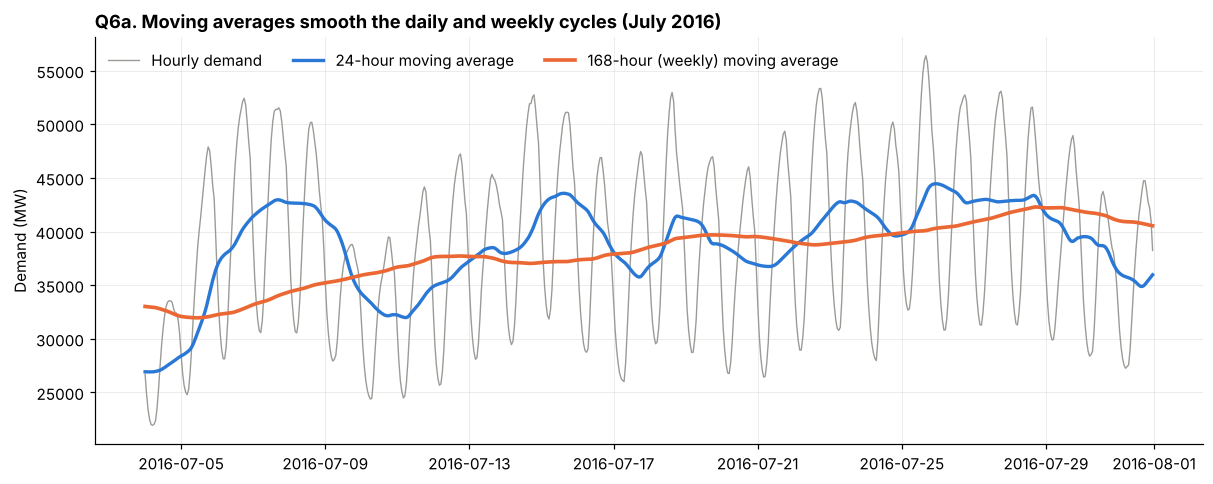

In [7]:
window = feat.loc["2016-07-04":"2016-07-31"]

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(window.index, window["PJME_MW"], color=GREY, lw=0.9, label="Hourly demand")
ax.plot(window.index, window["rolling_mean_24"], color=BLUE, lw=2.2, label="24-hour moving average")
ax.plot(window.index, window["rolling_mean_168"], color=ORANGE, lw=2.4, label="168-hour (weekly) moving average")
ax.set(title="Q6a. Moving averages smooth the daily and weekly cycles (July 2016)", ylabel="Demand (MW)")
ax.legend(frameon=False, loc="upper left", ncol=3)
plt.show()

In [8]:
# How well does each moving average track the real demand?
for col in ["rolling_mean_24", "rolling_mean_168"]:
    print(f"{col:17s} correlation with demand = {feat[col].corr(feat['PJME_MW']):.3f}")

# Demand variability that remains after smoothing
print()
print("Std dev of hourly demand:           ", f"{feat['PJME_MW'].std():,.0f} MW")
print("Std dev of 24-hour moving average:  ", f"{feat['rolling_mean_24'].std():,.0f} MW")
print("Std dev of 168-hour moving average: ", f"{feat['rolling_mean_168'].std():,.0f} MW")

rolling_mean_24   correlation with demand = 0.696
rolling_mean_168  correlation with demand = 0.564

Std dev of hourly demand:            6,467 MW
Std dev of 24-hour moving average:   4,687 MW
Std dev of 168-hour moving average:  3,983 MW


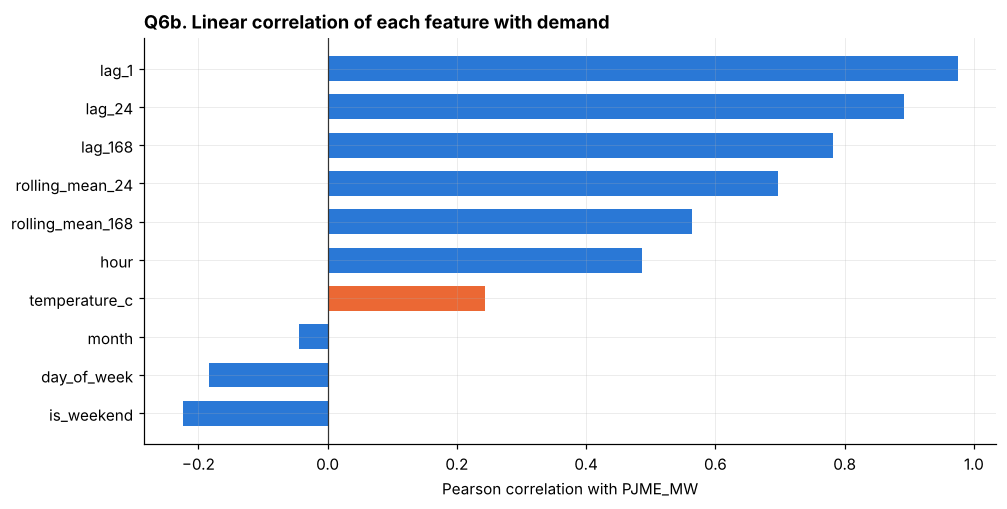

,is_weekend,day_of_week,month,temperature_c,hour,rolling_mean_168,rolling_mean_24,lag_168,lag_24,lag_1
correlation,-0.22,-0.18,-0.04,0.24,0.49,0.56,0.70,0.78,0.89,0.97


In [9]:
# Which engineered features are most related to the target?
numeric = ["temperature_c", "hour", "day_of_week", "month", "is_weekend",
           "lag_1", "lag_24", "lag_168", "rolling_mean_24", "rolling_mean_168"]
corr = feat[numeric + ["PJME_MW"]].corr()["PJME_MW"].drop("PJME_MW").sort_values()

fig, ax = plt.subplots(figsize=(10, 4.8))
colors = [ORANGE if c == "temperature_c" else BLUE for c in corr.index]
ax.barh(corr.index, corr.values, color=colors, height=0.65)
ax.axvline(0, color=DARK, lw=0.8)
ax.set(title="Q6b. Linear correlation of each feature with demand", xlabel="Pearson correlation with PJME_MW")
plt.show()
corr.round(3).to_frame("correlation").T

**Interpretation**
- The 24-hour average removes the daily up-and-down and shows the **multi-day level**: it rises during hot spells (for example 4 to 8 July and 25 to 28 July 2016) and falls in cooler days. The 168-hour average removes the weekly cycle as well and shows the slow drift of the month, rising from about 33,000 to 42,000 MW as summer heat built up.
- Smoothing reduces variability strongly: the standard deviation falls from **6,467 MW** (hourly) to **4,687 MW** (24-hour average) and **3,983 MW** (168-hour average).
- A moving average **trails behind** the real demand (it is based only on the past), so it is a poor *direct* predictor: its correlation with demand is **0.70** (24 h) and **0.56** (168 h), compared with **0.97** for `lag_1`, and its naive forecast errors in Q5 were the largest (12.2% and 13.7%). Its value is as **context**: it tells the model whether the recent level is a normal week or a heat wave.
- **Feature ranking by linear correlation:** `lag_1` (0.97), `lag_24` (0.89), `lag_168` (0.78), `rolling_mean_24` (0.70), `rolling_mean_168` (0.56), `hour` (0.49), then `temperature_c` (0.24). `is_weekend`, `day_of_week` and `month` look weak (-0.22, -0.18, -0.04), but Q2 to Q4 showed strong patterns in them. Pearson correlation only detects straight-line relationships, and these features act in cycles or curves, so a low value does **not** mean they are unimportant. Encoding `hour` and `month` as sine and cosine is worth considering.

## Summary of Task 1B

Six analytical questions were answered with at least one visualisation and an interpretation each:

| Q | Topic | Uses lag / moving average |
|---|---|---|
| Q1 | long-term trend | 365-day moving average |
| Q2 | daily and weekly pattern | |
| Q3 | seasonal pattern | |
| Q4 | temperature and demand | |
| Q5 | lag effects | `lag_1`, `lag_24`, `lag_168` |
| Q6 | moving averages | `rolling_mean_24`, `rolling_mean_168` |